# Custom Equal Weight Portfolio
Enter the list of hedge funds you want to include in the equal weight portfolio along with the SP500.

In [97]:
# 1. Define the list of hedge funds to include in the portfolio
hf_list = [
    "quantstream",
    "adar1",
    "enko",
    "shiprock",
    "vadantia"
]


In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", None)

CUTOFF_DATE = pd.to_datetime('2021-01-01')

# 2. Load the financial data
df = pd.read_csv("./data/concat_hf_data.csv", parse_dates=True).set_index("date")
df.index = pd.to_datetime(df.index)

# Ensure sp500 is in the columns for the portfolio
if "sp500" not in hf_list:
    assets = hf_list + ["sp500"]
else:
    assets = hf_list

# Check for missing funds
missing = [f for f in assets if f not in df.columns]
if missing:
    print(f"Warning: the following funds are missing from the data: {missing}")
    assets = [f for f in assets if f in df.columns]

df = df[assets]
df.tail()

,quantstream,adar1,enko,shiprock,vadantia,sp500
date,,,,,,
2026-04-01,0.075052,0.021,0.0149,0.0132,0.0115,0.104927
2026-05-01,NaN,NaN,NaN,NaN,NaN,0.052633
2026-06-01,NaN,NaN,NaN,NaN,NaN,-0.009523
2026-07-01,NaN,NaN,NaN,NaN,NaN,-0.002048
2026-08-01,NaN,NaN,NaN,NaN,NaN,NaN


In [99]:
df[df.index >= pd.to_datetime(CUTOFF_DATE)].head()

,quantstream,adar1,enko,shiprock,vadantia,sp500
date,,,,,,
2021-01-01,0.037972,0.052,0.0069,0.0178,-0.0378,-0.010096
2021-02-01,0.006652,0.041,0.0125,0.0681,-0.0587,0.027575
2021-03-01,0.029242,-0.012,-0.0051,0.0370,-0.0502,0.043796
2021-04-01,0.051832,0.059,0.0037,0.0178,-0.0914,0.053369
2021-05-01,0.028972,0.113,0.0055,0.0371,-0.0537,0.006984


In [100]:
# 3. Construct the Equal Weight Portfolio
portfolio_returns = df[df.index >= pd.to_datetime(CUTOFF_DATE)].mean(axis=1)

df_port = pd.DataFrame({
    "Equal Weight Portfolio": portfolio_returns
})

df_port.head()

,Equal Weight Portfolio
date,
2021-01-01,0.011129
2021-02-01,0.016188
2021-03-01,0.007123
2021-04-01,0.015717
2021-05-01,0.022976


In [101]:
# 4. Define the metrics calculation function (like in the other notebooks)
def calculate_portfolio_metrics(returns_series):
    """
    Calculates various portfolio performance metrics given a time series of monthly returns.
    """
    if returns_series.empty or returns_series.isnull().all():
        return {
            "CAGR": np.nan,
            "Standard Deviation": np.nan,
            "Mean Return": np.nan,
            "Max Drawdown": np.nan,
            "Winning Months (%)": np.nan,
            "Sharpe Ratio": np.nan,
            "Calmar Ratio": np.nan
        }

    returns_series = returns_series.dropna()
    if returns_series.empty:
        return {
            "CAGR": np.nan,
            "Standard Deviation": np.nan,
            "Mean Return": np.nan,
            "Max Drawdown": np.nan,
            "Winning Months (%)": np.nan,
            "Sharpe Ratio": np.nan,
            "Calmar Ratio": np.nan
        }

    # 1. Annualized Mean Return
    mean_return = returns_series.mean() * 12

    # 2. Annualized Standard Deviation
    std_dev = returns_series.std() * np.sqrt(12)

    # 3. CAGR (Compound Annual Growth Rate)
    total_growth = (1 + returns_series).prod()
    num_periods = len(returns_series)
    num_years = num_periods / 12.0
    cagr = (total_growth**(1/num_years)) - 1

    # 4. Max Drawdown
    cumulative_returns = (1 + returns_series).cumprod()
    peak = cumulative_returns.expanding(min_periods=1).max()
    drawdown = (cumulative_returns - peak) / peak
    max_drawdown = drawdown.min()

    # 5. Percentage of Winning Months
    winning_months = (returns_series > 0).sum()
    total_months = len(returns_series)
    percent_winning_months = (winning_months / total_months) * 100 if total_months > 0 else np.nan

    # 6. Sharpe Ratio (assuming risk-free rate is 0)
    sharpe_ratio = mean_return / std_dev if std_dev != 0 else np.nan

    # 7. Calmar Ratio
    calmar_ratio = cagr / abs(max_drawdown) if max_drawdown != 0 else np.nan

    metrics = {
        "CAGR": cagr,
        "Standard Deviation": std_dev,
        "Mean Return": mean_return,
        "Max Drawdown": max_drawdown,
        "Winning Months (%)": percent_winning_months,
        "Sharpe Ratio": sharpe_ratio,
        "Calmar Ratio": calmar_ratio
    }

    return metrics


In [102]:
# 5. Calculate metrics for the Equal Weight Portfolio
metrics = calculate_portfolio_metrics(portfolio_returns)
metrics_df = pd.DataFrame([metrics], index=["Equal Weight Portfolio"]).T
display(metrics_df)

,Equal Weight Portfolio
CAGR,0.278294
Standard Deviation,0.074268
Mean Return,0.250716
Max Drawdown,-0.024958
Winning Months (%),79.104478
Sharpe Ratio,3.375819
Calmar Ratio,11.150591


In [103]:
# 6. Calculate and compare metrics with individual assets and SP500
all_metrics = {}
for asset in assets:
    all_metrics[asset] = calculate_portfolio_metrics(df[df.index >= pd.to_datetime(CUTOFF_DATE)][asset])

all_metrics["Equal Weight Portfolio"] = calculate_portfolio_metrics(portfolio_returns)

comparison_df = pd.DataFrame(all_metrics)
display(comparison_df)

,quantstream,adar1,enko,shiprock,vadantia,sp500,Equal Weight Portfolio
CAGR,0.383713,0.367093,0.174790,0.230525,0.353571,0.147644,0.278294
Standard Deviation,0.111999,0.168697,0.138958,0.097299,0.213681,0.152159,0.074268
Mean Return,0.335375,0.330188,0.171694,0.213881,0.328256,0.149897,0.250716
Max Drawdown,-0.094598,-0.106296,-0.229971,-0.087378,-0.231291,-0.238673,-0.024958
Winning Months (%),85.937500,71.875000,71.875000,79.687500,70.312500,64.179104,79.104478
Sharpe Ratio,2.994449,1.957282,1.235582,2.198191,1.536200,0.985131,3.375819
Calmar Ratio,4.056231,3.453489,0.760050,2.638252,1.528684,0.618601,11.150591


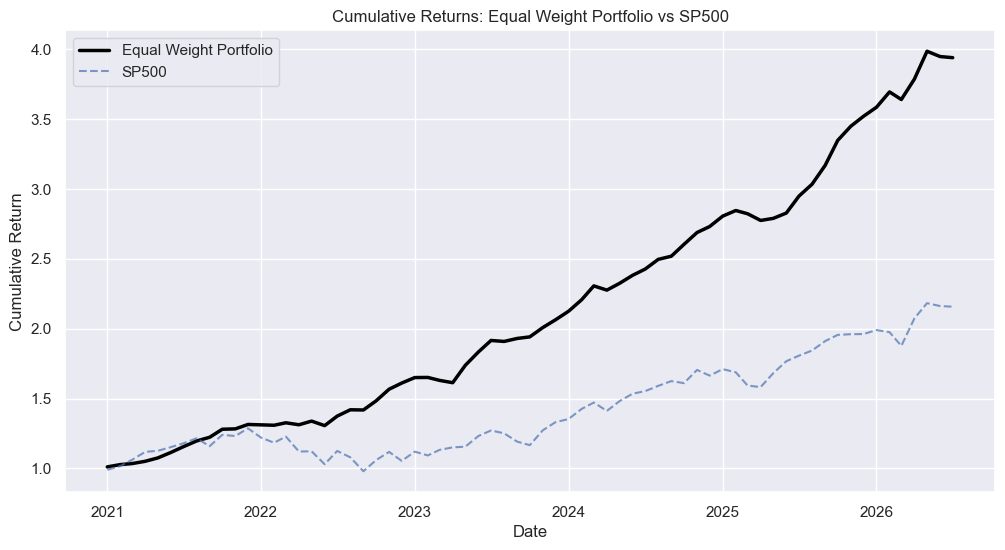

In [104]:
# 7. Plot cumulative returns
plt.figure(figsize=(12, 6))

cumulative_port = (1 + portfolio_returns).cumprod()
plt.plot(cumulative_port.index, cumulative_port, label="Equal Weight Portfolio", linewidth=2.5, color="black")

if "sp500" in df.columns:
    cumulative_sp500 = (1 + df[df.index >= pd.to_datetime(CUTOFF_DATE)]["sp500"]).cumprod()
    plt.plot(cumulative_sp500.index, cumulative_sp500, label="SP500", linestyle="--", alpha=0.7)

plt.title("Cumulative Returns: Equal Weight Portfolio vs SP500")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.legend()
plt.grid(True)
plt.show()